# 4.2 SVM sur TF-IDF caractères : Dataset 2 (extrait final, 60 000 images)

Le SVM ré-entraîné sur l'extrait final : OCR de 12 000 documents, 9 572 en train et 2 394 en test
une fois retirés les documents où l'OCR n'a rien lu. C'est notre modèle texte de référence.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.svm import LinearSVC

from outils_4 import ARTEFACTS_60K, load_corpus_60k, top_two

train, test = load_corpus_60k()
y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
print(f"Train : {len(train)} | Test : {len(test)}")

Train : 9572 | Test : 2394


## 1. Entraînement (C choisi par validation croisée sur le train)

In [2]:
vectoriseur = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
X_train = vectoriseur.fit_transform(train["text"])
X_test = vectoriseur.transform(test["text"])

grid = GridSearchCV(LinearSVC(random_state=42, max_iter=5000), {"C": [0.01, 0.1, 0.3, 1, 3, 10]}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
classes = list(grid.classes_)

# un score par classe, le plus grand gagne
scores_test = grid.decision_function(X_test)
print("Meilleur C :", grid.best_params_["C"])
print(f"Accuracy test : {accuracy_score(y_test, grid.predict(X_test)):.1%}")

Meilleur C : 1
Accuracy test : 86.7%


## 2. Le modèle sait-il quand il se trompe ?

Un petit écart entre les deux meilleurs scores veut dire que le modèle hésite.

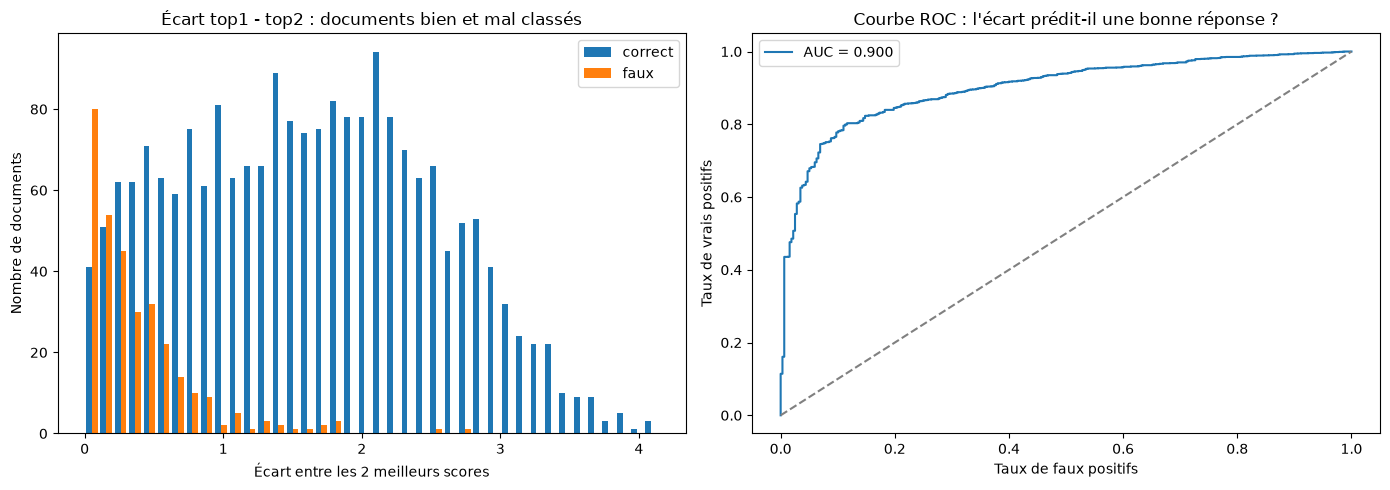

In [3]:
ecarts = top_two(scores_test, classes)
juste = (ecarts["top1"] == y_test).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist([ecarts["ecart"][juste], ecarts["ecart"][~juste]], bins=40, label=["correct", "faux"])
axes[0].set_xlabel("Écart entre les 2 meilleurs scores")
axes[0].set_ylabel("Nombre de documents")
axes[0].set_title("Écart top1 - top2 : documents bien et mal classés")
axes[0].legend()

# ROC : est-ce que l'écart permet de deviner si le modèle a juste ?
faux_positifs, vrais_positifs, _ = roc_curve(juste, ecarts["ecart"])
auc = roc_auc_score(juste, ecarts["ecart"])
axes[1].plot(faux_positifs, vrais_positifs, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC : l'écart prédit-il une bonne réponse ?")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. La zone d'incertitude : les 800 documents où le modèle hésite le plus

In [4]:
seuil = np.sort(ecarts["ecart"])[799] + 1e-9
zone = (ecarts["ecart"] < seuil).to_numpy()

print(f"Zone : {zone.sum()} documents (écart < {seuil:.3f})")
print(f"Accuracy dans la zone : {juste[zone].sum()}/{zone.sum()} = {juste[zone].mean():.1%} (contre {juste.mean():.1%} sur tout le test)")

Zone : 800 documents (écart < 0.869)
Accuracy dans la zone : 510/800 = 63.7% (contre 86.7% sur tout le test)


Les scores du test viennent du modèle ci-dessus. Ceux du train sont calculés par validation
croisée (`cross_val_predict`) : chaque document est noté par un SVM qui ne l'a pas vu.

In [5]:
scores_train = cross_val_predict(LinearSVC(C=grid.best_params_["C"], random_state=42, max_iter=5000),
                                 X_train, y_train, cv=5, method="decision_function", n_jobs=-1)

tous = pd.concat([train.assign(ensemble="train"), test.assign(ensemble="test")], ignore_index=True)
scores = pd.DataFrame(np.vstack([scores_train, scores_test]), columns=[f"score_{c}" for c in classes])
pd.concat([tous[["filepath", "label", "ensemble"]], scores], axis=1).to_csv(f"{ARTEFACTS_60K}/scores_svm_60k.csv", index=False)
print("Enregistré : scores_svm_60k.csv")

Enregistré : scores_svm_60k.csv
